# Peptide Exploratory Data Analysis

This notebook explores the peptide-level measurements in the AMP PD dataset.

The goals are to:

1. Understand peptide coverage across patient visits.
2. Reshape the peptide data into a visit-level feature matrix.
3. Match peptide measurements with clinical UPDRS outcomes.
4. Explore preliminary associations between peptide abundance and UPDRS Part 3.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("../data/raw")

peptides = pd.read_csv(DATA_DIR / "train_peptides.csv")
clinical = pd.read_csv(DATA_DIR / "train_clinical_data.csv")

print("Peptide data shape:", peptides.shape)
print("Clinical data shape:", clinical.shape)

Peptide data shape: (981834, 6)
Clinical data shape: (2615, 8)


In [2]:
print("Unique patients:", peptides["patient_id"].nunique())
print("Unique visits:", peptides["visit_id"].nunique())
print("Unique peptides:", peptides["Peptide"].nunique())
print("Unique proteins represented:", peptides["UniProt"].nunique())

print()
print("Columns:")
print(peptides.columns.tolist())

peptides.head()

Unique patients: 248
Unique visits: 1113
Unique peptides: 968
Unique proteins represented: 227

Columns:
['visit_id', 'visit_month', 'patient_id', 'UniProt', 'Peptide', 'PeptideAbundance']


,visit_id,visit_month,patient_id,UniProt,Peptide,PeptideAbundance
0,55_0,0,55,O00391,NEQEQPLGQWHLS,11254.3
1,55_0,0,55,O00533,GNPEPTFSWTK,102060.0
2,55_0,0,55,O00533,IEIPSSVQQVPTIIK,174185.0
3,55_0,0,55,O00533,KPQSAVYSTGSNGILLC(UniMod_4)EAEGEPQPTIK,27278.9
4,55_0,0,55,O00533,SMEQNGPGLEYR,30838.7


## Peptide Coverage Across Visits

Although there are 968 unique peptides in the full dataset, not every peptide is measured at every visit.

We calculate how many unique peptides are available for each visit.

In [3]:
peptides_per_visit = (
    peptides.groupby("visit_id")["Peptide"]
    .nunique()
)

print("Peptides measured per visit:")
print(peptides_per_visit.describe())

Peptides measured per visit:
count    1113.000000
mean      882.150943
std        69.156328
min        94.000000
25%       878.000000
50%       903.000000
75%       917.000000
max       947.000000
Name: Peptide, dtype: float64


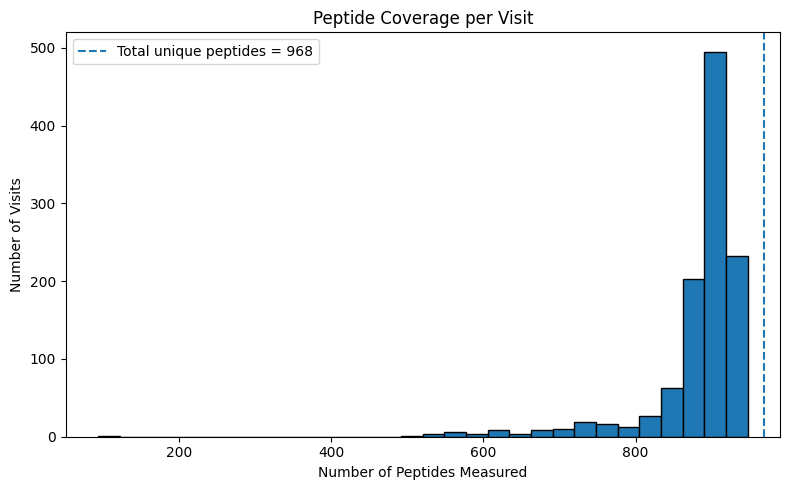

In [4]:
plt.figure(figsize=(8, 5))

plt.hist(
    peptides_per_visit,
    bins=30,
    edgecolor="black"
)

plt.axvline(
    peptides["Peptide"].nunique(),
    linestyle="--",
    label="Total unique peptides = 968"
)

plt.xlabel("Number of Peptides Measured")
plt.ylabel("Number of Visits")
plt.title("Peptide Coverage per Visit")

plt.legend()
plt.tight_layout()
plt.show()

In [5]:
print("Missing PeptideAbundance values:",
      peptides["PeptideAbundance"].isna().sum())

print(
    "Percent missing:",
    round(peptides["PeptideAbundance"].isna().mean() * 100, 2)
)

Missing PeptideAbundance values: 0
Percent missing: 0.0


## Reshaping Peptide Data

The original peptide dataset is stored in long format, where each row represents one peptide measurement.

For analysis and modeling, we reshape it so that:

- each row represents one visit
- each peptide becomes a feature
- the values are peptide abundances

In [6]:
peptide_wide = peptides.pivot_table(
    index="visit_id",
    columns="Peptide",
    values="PeptideAbundance",
    aggfunc="first"
)

print("Peptide data in wide format:")
print("Rows (visits):", peptide_wide.shape[0])
print("Columns (peptides):", peptide_wide.shape[1])

peptide_wide.head()

Peptide data in wide format:
Rows (visits): 1113
Columns (peptides): 968


Peptide,AADDTWEPFASGK,AAFGQGSGPIMLDEVQC(UniMod_4)TGTEASLADC(UniMod_4)K,AAFTEC(UniMod_4)C(UniMod_4)QAADK,AANEVSSADVK,AATGEC(UniMod_4)TATVGKR,AATVGSLAGQPLQER,AAVYHHFISDGVR,ADDKETC(UniMod_4)FAEEGK,ADDKETC(UniMod_4)FAEEGKK,ADDLGKGGNEESTKTGNAGSR,...,YSLTYIYTGLSK,YTTEIIK,YVGGQEHFAHLLILR,YVM(UniMod_35)LPVADQDQC(UniMod_4)IR,YVMLPVADQDQC(UniMod_4)IR,YVNKEIQNAVNGVK,YWGVASFLQK,YYC(UniMod_4)FQGNQFLR,YYTYLIMNK,YYWGGQYTWDMAK
visit_id,,,,,,,,,,,,,,,,,,,,,
10053_0,6580710.0,31204.4,7735070.0,NaN,NaN,NaN,46620.3,236144.0,NaN,NaN,...,202274.0,NaN,4401830.0,77482.6,583075.0,76705.7,104260.0,530223.0,NaN,7207.30
10053_12,6333510.0,52277.6,5394390.0,NaN,NaN,NaN,57554.5,108298.0,45885.4,NaN,...,201009.0,NaN,5001750.0,36745.3,355643.0,92078.1,123254.0,453883.0,49281.9,25332.80
10053_18,7129640.0,61522.0,7011920.0,35984.7,17188.0,19787.3,36029.4,708729.0,5067790.0,30838.2,...,220728.0,NaN,5424380.0,39016.0,496021.0,63203.6,128336.0,447505.0,52389.1,21235.70
10138_12,7404780.0,46107.2,10610900.0,NaN,20910.2,66662.3,55253.9,79575.5,6201210.0,26720.0,...,188362.0,9433.71,3900280.0,48210.3,328482.0,89822.1,129964.0,552232.0,65657.8,9876.98
10138_24,13788300.0,56910.3,6906160.0,13785.5,11004.2,63672.7,36819.8,34160.9,2117430.0,15645.2,...,206187.0,6365.15,3521800.0,69984.6,496737.0,80919.3,111799.0,NaN,56977.6,4903.09


In [7]:
peptide_missing = (
    peptide_wide.isna().mean() * 100
).sort_values(ascending=False)

print("Peptide missingness summary:")
print(peptide_missing.describe())

print()
print("10 peptides with the most missing measurements:")
print(peptide_missing.head(10))

Peptide missingness summary:
count    968.000000
mean       8.868704
std       10.515959
min        0.000000
25%        1.437556
50%        4.582210
75%       12.151842
max       56.064690
dtype: float64

10 peptides with the most missing measurements:
Peptide
QALPQVR                   56.064690
EPQVYTLPPSRDELTK          49.415993
TPSGLYLGTC(UniMod_4)ER    46.990117
SLEDQVEMLR                46.181491
HYEGSTVPEK                45.642408
VPEEDLKR                  45.552561
VAPDEHPILLTEAPLNPK        44.654088
LTASAPGYLAITK             44.384546
QQLVETHMAR                44.204852
ALVQQMEQLR                43.306379
dtype: float64


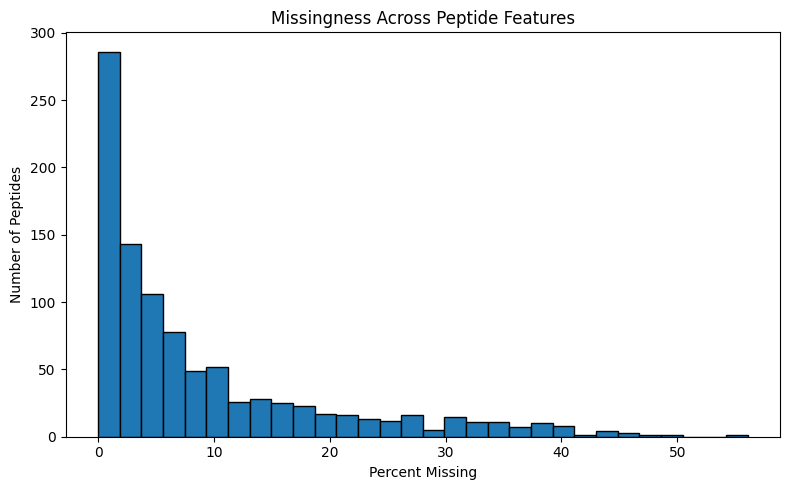

In [8]:
plt.figure(figsize=(8, 5))

plt.hist(
    peptide_missing,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Percent Missing")
plt.ylabel("Number of Peptides")
plt.title("Missingness Across Peptide Features")

plt.tight_layout()
plt.show()

## Matching Peptide Measurements with Clinical Data

To study whether peptide abundance is associated with Parkinson's severity, peptide measurements must be matched to clinical UPDRS scores from the same visit.

We use `visit_id` to connect the two datasets.

In [9]:
peptide_clinical = clinical[
    [
        "visit_id",
        "patient_id",
        "visit_month",
        "updrs_1",
        "updrs_2",
        "updrs_3",
        "updrs_4"
    ]
].merge(
    peptide_wide,
    left_on="visit_id",
    right_index=True,
    how="inner"
)

print("Matched clinical + peptide visits:",
      peptide_clinical.shape[0])

print("Number of peptide features:",
      peptide_wide.shape[1])

peptide_clinical.head()

Matched clinical + peptide visits: 1068
Number of peptide features: 968


,visit_id,patient_id,visit_month,updrs_1,updrs_2,updrs_3,updrs_4,AADDTWEPFASGK,AAFGQGSGPIMLDEVQC(UniMod_4)TGTEASLADC(UniMod_4)K,AAFTEC(UniMod_4)C(UniMod_4)QAADK,...,YSLTYIYTGLSK,YTTEIIK,YVGGQEHFAHLLILR,YVM(UniMod_35)LPVADQDQC(UniMod_4)IR,YVMLPVADQDQC(UniMod_4)IR,YVNKEIQNAVNGVK,YWGVASFLQK,YYC(UniMod_4)FQGNQFLR,YYTYLIMNK,YYWGGQYTWDMAK
0,55_0,55,0,10.0,6.0,15.0,NaN,8984260.0,53855.6,8579740.0,...,201158.0,16492.3,3810270.0,106894.0,580667.0,131155.0,165851.0,437305.0,46289.2,14898.4
2,55_6,55,6,8.0,10.0,34.0,NaN,8279770.0,45251.9,8655890.0,...,171079.0,13198.8,4119520.0,113385.0,514861.0,103512.0,144607.0,457891.0,40047.7,20703.9
4,55_12,55,12,10.0,10.0,41.0,0.0,8382390.0,53000.9,8995640.0,...,231772.0,17873.8,5474140.0,116286.0,711815.0,136943.0,181763.0,452253.0,54725.1,21841.1
8,55_36,55,36,17.0,18.0,51.0,0.0,10671500.0,58108.4,9985420.0,...,185290.0,18580.5,2659660.0,90936.9,679163.0,128593.0,203680.0,498621.0,52792.7,13973.7
15,942_6,942,6,8.0,2.0,21.0,NaN,6177730.0,42682.6,3596660.0,...,226314.0,6399.8,NaN,57571.4,480951.0,80001.2,79661.9,573300.0,48005.8,15674.1


In [10]:
print(
    "Matched visits with UPDRS 3 available:",
    peptide_clinical["updrs_3"].notna().sum()
)

print(
    "Matched visits with UPDRS 3 missing:",
    peptide_clinical["updrs_3"].isna().sum()
)

Matched visits with UPDRS 3 available: 1058
Matched visits with UPDRS 3 missing: 10


## Preliminary Peptide Associations with UPDRS 3

We calculate simple Pearson correlations between individual peptide abundances and UPDRS Part 3.

These correlations are exploratory and do not establish causation or identify confirmed biomarkers.

In [11]:
peptide_columns = peptide_wide.columns.tolist()

correlations = {}

for peptide in peptide_columns:

    valid = peptide_clinical[
        [peptide, "updrs_3"]
    ].dropna()

    # Require enough observations for a useful correlation
    if len(valid) >= 100:
        correlations[peptide] = (
            valid[peptide].corr(valid["updrs_3"])
        )

peptide_correlations = (
    pd.Series(correlations)
    .dropna()
    .sort_values()
)

print("Number of peptides evaluated:",
      len(peptide_correlations))

print()
print("Strongest negative correlations:")
print(peptide_correlations.head(10))

print()
print("Strongest positive correlations:")
print(peptide_correlations.tail(10))

Number of peptides evaluated: 968

Strongest negative correlations:
DQGNQEQDPNISNGEEEEEKEPGEVGTHNDNQER       -0.226285
GYPGVQAPEDLEWER                          -0.225110
ALEYIENLR                                -0.222817
AYQGVAAPFPK                              -0.222205
IEIPSSVQQVPTIIK                          -0.219616
TLKIENVSYQDKGNYR                         -0.218292
KPQSAVYSTGSNGILLC(UniMod_4)EAEGEPQPTIK   -0.212320
LNMHMNVQNGKWDSDPSGTK                     -0.207509
LIADLGSTSITNLGFR                         -0.204896
LLPAQLPAEKEVGPPLPQEAVPLQK                -0.203518
dtype: float64

Strongest positive correlations:
GLPAPIEK                                                   0.125678
VTSIQDWVQK                                                 0.126486
NFPPSQDASGDLYTTSSQLTLPATQC(UniMod_4)LAGK                   0.126634
LRTEGDGVYTLNNEKQWINK                                       0.126806
QFTSSTSYNR                                                 0.126932
VMPIC(UniMod_4)LPSKDYAEVGR       

In [12]:
top_absolute = (
    peptide_correlations
    .abs()
    .sort_values(ascending=False)
    .head(15)
)

top_peptides = peptide_correlations.loc[
    top_absolute.index
].sort_values()

top_peptides

DQGNQEQDPNISNGEEEEEKEPGEVGTHNDNQER       -0.226285
GYPGVQAPEDLEWER                          -0.225110
ALEYIENLR                                -0.222817
AYQGVAAPFPK                              -0.222205
IEIPSSVQQVPTIIK                          -0.219616
TLKIENVSYQDKGNYR                         -0.218292
KPQSAVYSTGSNGILLC(UniMod_4)EAEGEPQPTIK   -0.212320
LNMHMNVQNGKWDSDPSGTK                     -0.207509
LIADLGSTSITNLGFR                         -0.204896
LLPAQLPAEKEVGPPLPQEAVPLQK                -0.203518
KLSENTDFLAPGVSSFTDSNQQESITK              -0.200972
ISYGNDALMPSLTETK                         -0.200176
VNGSPVDNHPFAGDVVFPR                      -0.195712
VFNTPEGVPSAPSSLK                         -0.194913
VHKEDDGVPVIC(UniMod_4)QVEHPAVTGNLQTQR    -0.192272
dtype: float64

In [13]:
# Check whether the strongest correlations are positive or negative

print("Strongest negative correlation:")
print(peptide_correlations.head(1))

print("\nStrongest positive correlation:")
print(peptide_correlations.tail(1))

print("\nTop 15 correlations ranked by absolute value:")
print(top_peptides)

Strongest negative correlation:
DQGNQEQDPNISNGEEEEEKEPGEVGTHNDNQER   -0.226285
dtype: float64

Strongest positive correlation:
HYTNPSQDVTVPC(UniMod_4)PVPPPPPC(UniMod_4)C(UniMod_4)HPR    0.151232
dtype: float64

Top 15 correlations ranked by absolute value:
DQGNQEQDPNISNGEEEEEKEPGEVGTHNDNQER       -0.226285
GYPGVQAPEDLEWER                          -0.225110
ALEYIENLR                                -0.222817
AYQGVAAPFPK                              -0.222205
IEIPSSVQQVPTIIK                          -0.219616
TLKIENVSYQDKGNYR                         -0.218292
KPQSAVYSTGSNGILLC(UniMod_4)EAEGEPQPTIK   -0.212320
LNMHMNVQNGKWDSDPSGTK                     -0.207509
LIADLGSTSITNLGFR                         -0.204896
LLPAQLPAEKEVGPPLPQEAVPLQK                -0.203518
KLSENTDFLAPGVSSFTDSNQQESITK              -0.200972
ISYGNDALMPSLTETK                         -0.200176
VNGSPVDNHPFAGDVVFPR                      -0.195712
VFNTPEGVPSAPSSLK                         -0.194913
VHKEDDGVPVIC(UniMod_4)QVEHPAV

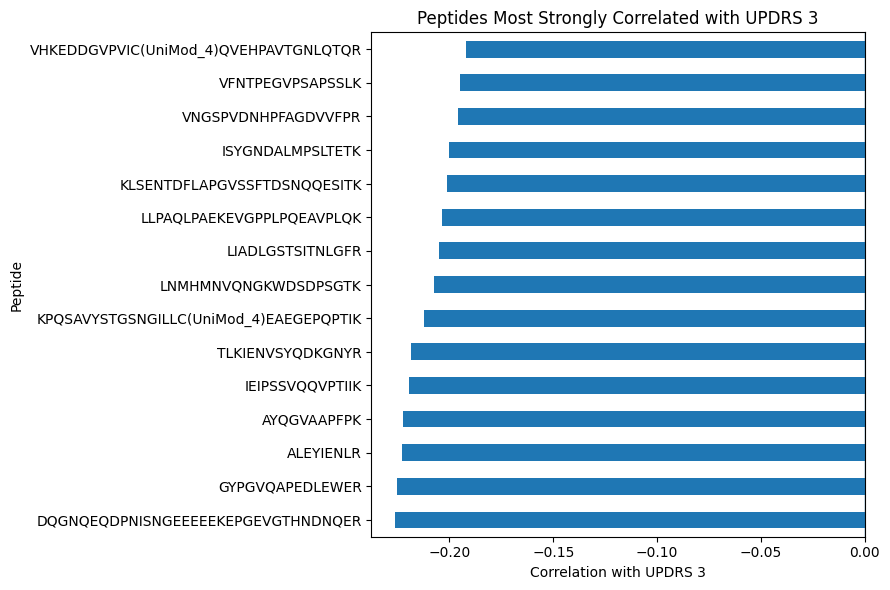

In [14]:
plt.figure(figsize=(9, 6))

top_peptides.plot(
    kind="barh"
)

plt.axvline(0, linewidth=1)

plt.xlabel("Correlation with UPDRS 3")
plt.ylabel("Peptide")
plt.title("Peptides Most Strongly Correlated with UPDRS 3")

plt.tight_layout()
plt.show()

In [15]:
strongest_peptide = (
    peptide_correlations
    .abs()
    .idxmax()
)

strongest_corr = peptide_correlations[
    strongest_peptide
]

print("Strongest peptide association:")
print("Peptide:", strongest_peptide)
print("Correlation with UPDRS 3:",
      round(strongest_corr, 3))

Strongest peptide association:
Peptide: DQGNQEQDPNISNGEEEEEKEPGEVGTHNDNQER
Correlation with UPDRS 3: -0.226


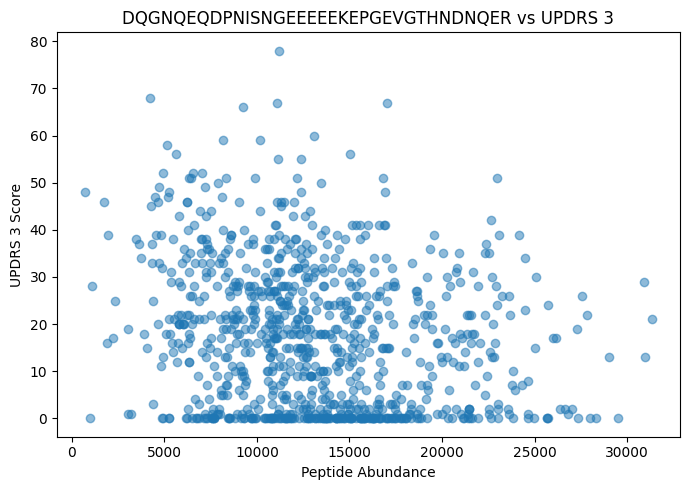

In [16]:
plot_data = peptide_clinical[
    [strongest_peptide, "updrs_3"]
].dropna()

plt.figure(figsize=(7, 5))

plt.scatter(
    plot_data[strongest_peptide],
    plot_data["updrs_3"],
    alpha=0.5
)

plt.xlabel("Peptide Abundance")
plt.ylabel("UPDRS 3 Score")
plt.title(
    f"{strongest_peptide} vs UPDRS 3"
)

plt.tight_layout()
plt.show()

## Initial Findings

- The peptide dataset contains **968 unique peptides** measured across **1,113 visits**.
- Most visits have broad peptide coverage, with a median of approximately **903 peptides measured per visit**.
- After reshaping the data into visit-level features, average peptide missingness was approximately **8.9%**, although some peptides were missing in more than 50% of visits.
- **1,068 visits** had matching peptide and clinical data, and **1,058** of these had an available UPDRS Part 3 score.
- Individual peptide correlations with UPDRS 3 were generally modest. The strongest observed correlation was approximately **-0.23**.
- These results suggest that no single peptide has a strong simple linear relationship with UPDRS 3 severity.
- A multivariable modeling approach may therefore be more useful for determining whether combinations of peptide measurements are associated with Parkinson's disease severity or progression.